# Gradient descent and support vector machines

A UCL MATH0011 group project. The first half implements gradient descent for functions of two variables. The second half trains a support vector machine by minimising a hinge loss with `scipy.optimize.minimize`.

## Part 1: Gradient descent

The gradient of $F(x, y)$ is approximated with forward differences of step $h$:

$$\frac{\partial F}{\partial x} \approx \frac{F(x+h, y) - F(x, y)}{h}, \qquad \frac{\partial F}{\partial y} \approx \frac{F(x, y+h) - F(x, y)}{h}$$

Each step moves against the gradient with step size $k$:

$$\mathbf{a}_{i+1} = \mathbf{a}_i - k \nabla F(\mathbf{a}_i)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def approx_grad(f, v, h):
    return ((f(v[0] + h , v[1]) - f(v[0],v[1]))/h , (f(v[0], v[1] + h) - f(v[0],v[1]))/h)

Check against $F(x, y) = xy + x^2 + 2y + 3$, whose exact gradient is $(y + 2x,\ x + 2)$. At $(-4, 1)$ that is $(-7, -2)$.

In [2]:
def F(x, y):
    return x*y + x**2 + 2*y + 3
print(approx_grad(F, (-4, 1), 0.1))

(-6.900000000000013, -1.999999999999993)


In [3]:
def gradient_descent_sequence(f, a0, k, h, N):
    xs, ys = [a0[0]], [a0[1]]
    for i in range(N):
        xs.append(xs[len(xs)-1] - k * (approx_grad(f, (xs[len(xs)-1], ys[len(xs)-1]), h))[0])
        ys.append(ys[len(ys)-1] - k * (approx_grad(f, (xs[len(ys)-1], ys[len(ys)-1]), h))[1])
    return xs, ys

## Part 2: Plotting the paths

First a path on $g(x, y) = x^2 + 2y^2$, which has its minimum at the origin.

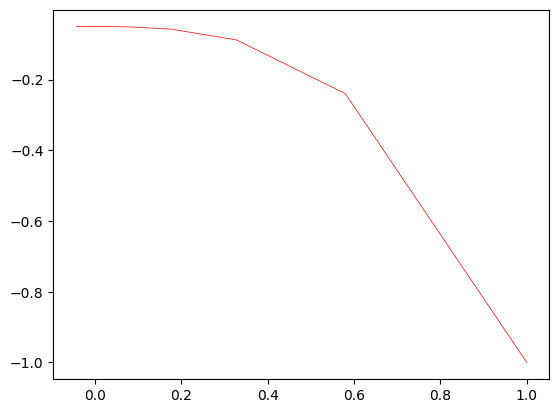

In [4]:
import numpy as np

def g(x,y):
    return x**2 + 2*y**2

#Plot Curve 
xs ,ys = gradient_descent_sequence(g,(1,-1),0.2,0.1,10)
plt.plot(xs, ys, 'r-', linewidth=0.5)

Contour plot of $g(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 6)^2$ (Himmelblau's function), which has four local minima.

In [5]:
def g(x, y):
    return ((x**2 + y -11)**2 + (x+y**2 - 6)**2)

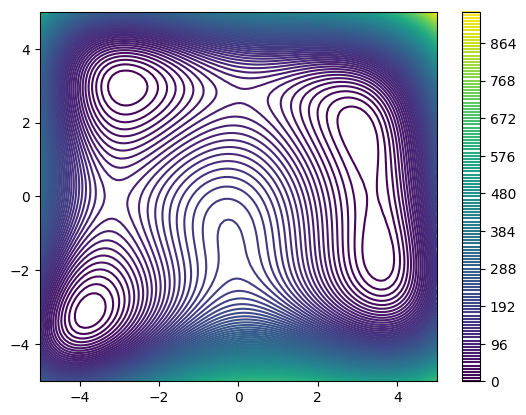

In [6]:
#Create Axis
x_grid_values = np.linspace(-5, 5, 100)
y_grid_values = np.linspace(-5, 5, 100)
xs, ys = np.meshgrid(x_grid_values, y_grid_values)

#Create Contour Map
zs = np.vectorize(g)(xs, ys)
plt.contour(xs, ys, zs, levels=150)
plt.colorbar()

Gradient descent from $(0, -3)$ on a filled contour plot. The red dot is the starting point.

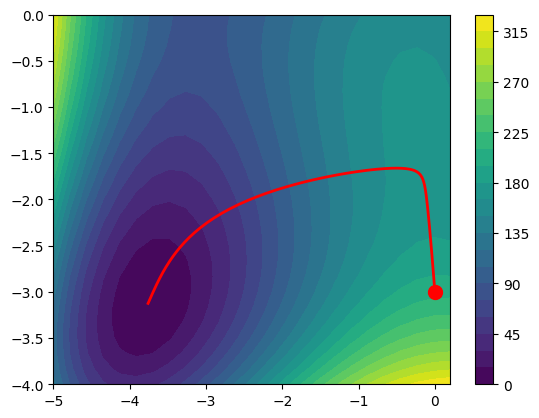

In [7]:
#Plot Curve
xs , ys = gradient_descent_sequence( g , [0, -3] ,  0.001 , 0.001 , 10000)
plt.plot(xs, ys, 'red', linewidth=2)

#Create Axis
x_grid_values = np.linspace(-5, 0.2, 25)
y_grid_values = np.linspace(-4, 0, 25)
xs, ys = np.meshgrid(x_grid_values, y_grid_values)

#Create Countourf Map and Colour Bar
zs = np.vectorize(g)(xs, ys)
plt.contourf(xs, ys, zs, levels=25)
plt.colorbar()
plt.scatter(0,-3,100,"red")

## Part 3: Simulated data

Random points around a centre, with `spread` controlling how far they scatter. A small spread gives well separated clusters, a larger one makes them overlap.

In [8]:
def generate_random_data(x0, y0, spread, n):
    x_list = []
    y_list = []
    for i in range(n):
        x_list.append(np.random.uniform(x0 - spread, x0 + spread))
        y_list.append(np.random.uniform(y0 - spread, y0 + spread))
    return x_list, y_list

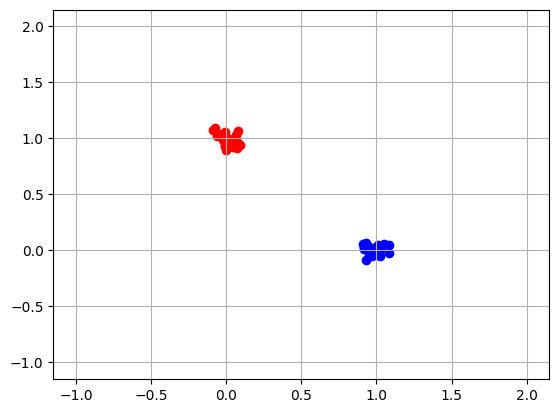

In [9]:
#Create Grid
xgv = np.linspace(-1, 2, 100)
ygv = np.linspace(-1, 2, 100)
plt.plot(xgv, ygv,'r-',linewidth = 0)
plt.grid()

#Generate and Plot Data
xlist , ylist = generate_random_data(0, 1, 0.1, 20)
plt.scatter(xlist, ylist, c = "red")
xlist , ylist = generate_random_data(1, 0, .1, 20)
plt.scatter(xlist, ylist, c = "blue")

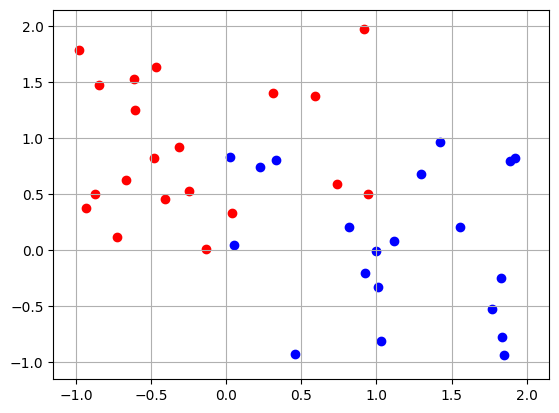

In [10]:
#Create Grid
xgv = np.linspace(-1, 2, 100)
ygv = np.linspace(-1, 2, 100)
plt.plot(xgv, ygv,'r-',linewidth = 0)
plt.grid()

#Generate and Plot Data
xlist , ylist = generate_random_data(0, 1, 1, 20)
plt.scatter(xlist, ylist, c = "red")
xlist , ylist = generate_random_data(1, 0, 1, 20)
plt.scatter(xlist, ylist, c = "blue")

## Part 4: The SVM loss

A hyperplane is the set of points with $\mathbf{w}^T \mathbf{x} = b$, and the margins are $\mathbf{w}^T \mathbf{x} = b \pm 1$. With labels $y_i \in \{1, -1\}$, the loss is

$$\lambda \lVert \mathbf{w} \rVert^2 + \frac{1}{n} \sum_{i=1}^n \max(0, 1 - y_i(\mathbf{w}^T \mathbf{x}_i - b))$$

with $\lambda = 0.01$. The first term favours a wide margin and the second penalises points on the wrong side of it.

In [11]:
def loss(bw, data):
    b = bw[0] #Bias Term
    w = bw[1:] #Weight Vector
    
    # Hinge Loss
    sum = 0
    #Assume data is list of tuples, containing 1D numpy arrays (vectors) (xi, yi) 
    for xi, yi in data:
        sum += max(0, 1 - float(yi) * (np.dot(np.transpose(w), xi) - b))
    
    # Return Loss Function
    return 0.01 * np.sum(w**2) + (1/len(data)) * sum

## Part 5: Minimising the loss

A trial of `scipy.optimize.minimize` on a simple function first. Its minimum is 2, at the point `testdata`.

In [12]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

In [13]:
def f(bw, data):
    return 2 + (bw[0] - data[0]) ** 2 + (bw[1] - data[1]) ** 2

testdata = np.array([1, 100])

In [14]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

bw = np.array([0, 0])

# Minimize the function
result = minimize(f, bw, args=(testdata,))
result

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 2.0
        x: [ 1.000e+00  1.000e+02]
      nit: 5
      jac: [ 0.000e+00  0.000e+00]
 hess_inv: [[ 5.000e-01 -9.060e-06]
            [-9.060e-06  5.003e-01]]
     nfev: 27
     njev: 9

The SVM demo. It generates two clouds of points, minimises the loss, and plots the hyperplane (solid) and margins (dashed).

In [15]:
def svm_demo(n, redCentre, blueCentre, spread):
    # Construct Grid
    xgv = np.linspace(min(redCentre[0], blueCentre[0])-spread, max(redCentre[0], blueCentre[0])+spread, 100)
    ygv = np.linspace(min(redCentre[1], blueCentre[1])-spread, max(redCentre[1], blueCentre[1])+spread, 100)
    plt.grid()
    
    #Generate Data for Plotting
    redDataGraph =  generate_random_data(redCentre[0], redCentre[1], spread, n)
    plt.scatter(redDataGraph[0], redDataGraph[1], c="red")
    blueDataGraph =  generate_random_data(blueCentre[0], blueCentre[1], spread, n)
    plt.scatter(blueDataGraph[0], blueDataGraph[1], c="blue")
    
    #Adjust Data to suit Loss Function
    redData = list(zip(np.array(list(zip(redDataGraph[0], redDataGraph[1]))), [1 for i in range(n)]))
    blueData = list(zip(np.array(list(zip(blueDataGraph[0], blueDataGraph[1]))), [-1 for i in range(n)]))
    data = redData + blueData
    
    bw = np.array([0, 1, -1])
    
    #Minimise the loss
    minimum = minimize(loss, bw, args=data)
    print(minimum)
    
    #Plot Hyperplane and Margins
    b, w = minimum.x[0], minimum.x[1:]
    x = np.linspace(min(redCentre[0], blueCentre[0])-2*spread, max(redCentre[0], blueCentre[0])+2*spread, 100)
    y1, y2, y3 = (b - w[0]*x)/w[1], (b + 1 - w[0]*x)/w[1], (b - 1 - w[0]*x)/w[1]
    plt.plot(x, y1, c = "black")
    plt.plot(x, y2, ls = '--', c = "black")
    plt.plot(x, y3, ls = '--', c = "black")

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 0.276668142172599
        x: [-2.966e-01  1.199e+00 -1.516e+00]
      nit: 16
      jac: [-2.500e-02  5.321e-03  1.633e-02]
 hess_inv: [[ 9.191e-01  4.476e-03  1.432e+00]
            [ 4.476e-03  2.966e-02  8.941e-03]
            [ 1.432e+00  8.941e-03  2.246e+00]]
     nfev: 325
     njev: 80


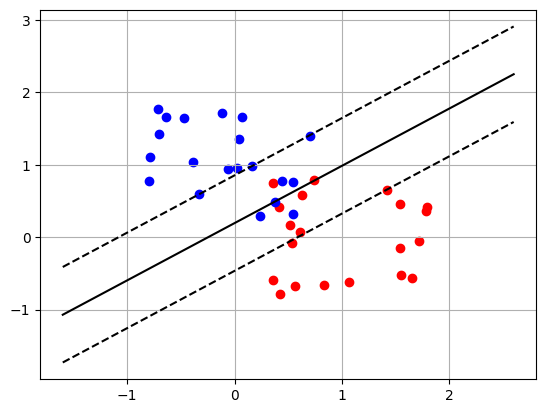

In [16]:
svm_demo(20, [1, 0], [0, 1], 0.8)